# ED408 — Statistical Machine Learning II Lab
## Experiment 10: Particle Swarm Optimisation on the Rosenbrock function

$$f(\mathbf x)=\sum_{i=1}^{d-1}\Big[100\,(x_{i+1}-x_i^2)^2+(1-x_i)^2\Big],\qquad \mathbf x^*=(1,\dots,1),\ f(\mathbf x^*)=0 .$$
Finding the curved, flat valley ("banana") is easy; moving along it to the minimum is slow, which is why Rosenbrock is a standard benchmark.

Each particle $i$ keeps a velocity and remembers its personal best $\mathbf p_i$. The whole swarm shares the global best $\mathbf g$:
$$\mathbf v_i \leftarrow w\,\mathbf v_i + c_1 r_1(\mathbf p_i-\mathbf x_i) + c_2 r_2(\mathbf g-\mathbf x_i),\qquad \mathbf x_i\leftarrow \mathbf x_i+\mathbf v_i$$
with $r_1,r_2\sim U(0,1)$ drawn per particle and per dimension. The inertia $w$ decreases linearly from 0.9 to 0.4, so the swarm explores early and exploits late.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110

def rosenbrock(X):
    """X: (n_particles, d) -> (n_particles,)"""
    return np.sum(100 * (X[:, 1:] - X[:, :-1]**2)**2 + (1 - X[:, :-1])**2, axis=1)

def pso(f, d, lo, hi, n_particles=30, iters=300, c1=2.0, c2=2.0, w_max=0.9, w_min=0.4, seed=0):
    rng = np.random.default_rng(seed)
    lo, hi = np.broadcast_to(lo, d).astype(float), np.broadcast_to(hi, d).astype(float)
    v_max = 0.2 * (hi - lo)
    X = rng.uniform(lo, hi, (n_particles, d))
    V = rng.uniform(-v_max, v_max, (n_particles, d))
    P, P_f = X.copy(), f(X)
    g = P[np.argmin(P_f)].copy()
    hist, snaps = [P_f.min()], [X.copy()]
    for t in range(iters):
        w = w_max - (w_max - w_min) * t / iters
        r1, r2 = rng.random((2, n_particles, d))
        V = np.clip(w*V + c1*r1*(P - X) + c2*r2*(g - X), -v_max, v_max)
        X = np.clip(X + V, lo, hi)
        fx = f(X)
        better = fx < P_f
        P[better], P_f[better] = X[better], fx[better]
        g = P[np.argmin(P_f)].copy()
        hist.append(P_f.min()); snaps.append(X.copy())
    return g, P_f.min(), np.array(hist), snaps

### 2-D run with the swarm drawn on the contour plot

PSO best: x = [1.00001 1.00001],  f = 3.251e-11   (true optimum (1, 1), f = 0)


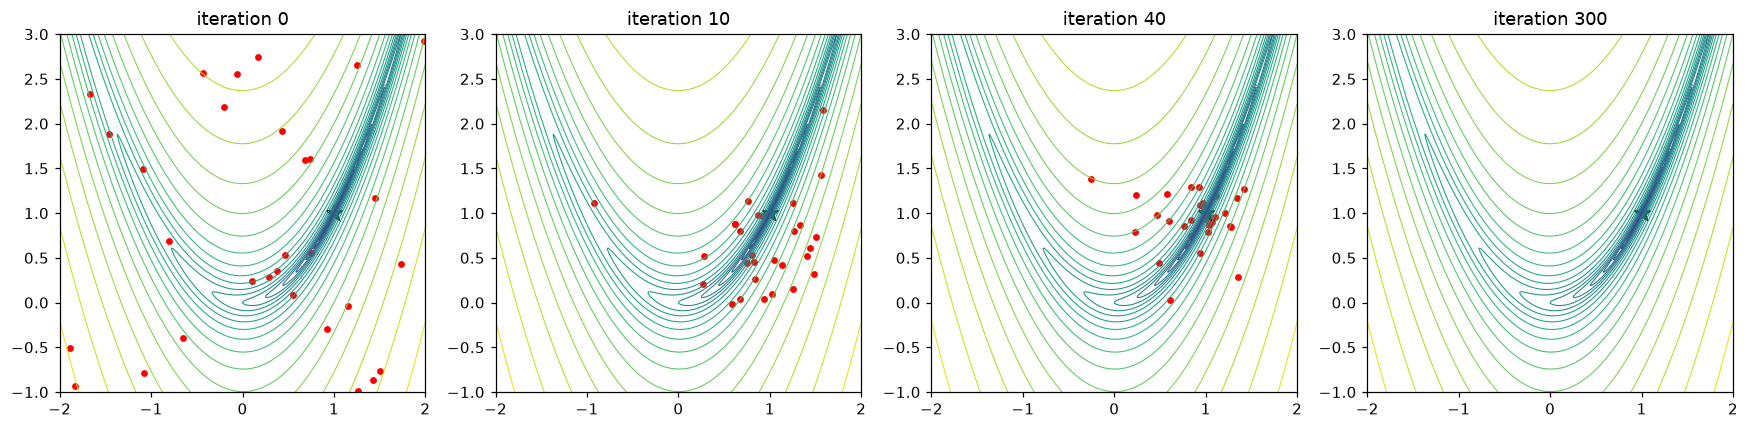

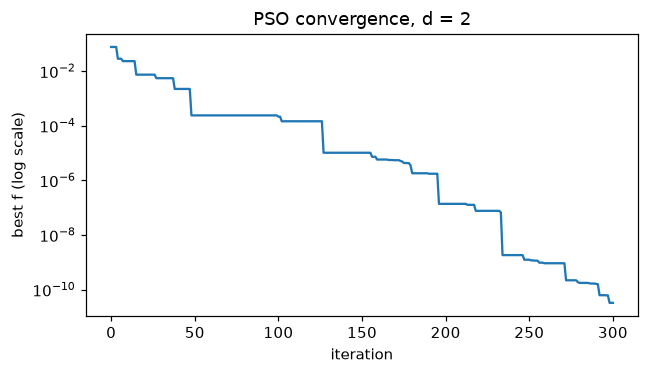

In [2]:
lo2, hi2 = np.array([-2, -1]), np.array([2, 3])
g, fg, hist, snaps = pso(rosenbrock, 2, lo2, hi2, n_particles=30, iters=300, seed=0)
print(f"PSO best: x = {np.round(g, 5)},  f = {fg:.3e}   (true optimum (1, 1), f = 0)")

xx, yy = np.meshgrid(np.linspace(-2, 2, 400), np.linspace(-1, 3, 400))
zz = rosenbrock(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, t in zip(ax, [0, 10, 40, 300]):
    a.contour(xx, yy, np.log10(zz + 1e-3), levels=25, cmap="viridis", linewidths=0.7)
    a.scatter(*snaps[t].T, c="r", s=12)
    a.scatter(1, 1, marker="*", c="k", s=120)
    a.set(title=f"iteration {t}", xlim=(-2, 2), ylim=(-1, 3))
plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 3.5))
plt.semilogy(hist)
plt.xlabel("iteration"); plt.ylabel("best f (log scale)"); plt.title("PSO convergence, d = 2")
plt.tight_layout(); plt.show()

### Higher dimensions and the effect of swarm size

The 2-D case is easy. Here we run $d=5$ and $d=10$, using 10 seeds per setting to see how consistent PSO is.


In [3]:
import pandas as pd

rows = []
for d in [2, 5, 10]:
    for n_particles in [20, 50]:
        res = [pso(rosenbrock, d, -5, 10, n_particles=n_particles, iters=2000, seed=s)[1] for s in range(10)]
        rows.append({"d": d, "particles": n_particles, "median best f": np.median(res),
                     "min best f": np.min(res), "max best f": np.max(res),
                     "runs with f < 1e-4": sum(r < 1e-4 for r in res)})
pd.DataFrame(rows)

,d,particles,median best f,min best f,max best f,runs with f < 1e-4
0,2,20,1.516092e-30,0.000000,1.814110e-26,10
1,2,50,0.000000e+00,0.000000,0.000000e+00,10
2,5,20,1.542798e-01,0.007775,4.671393e-01,0
3,5,50,5.649562e-02,0.027116,1.036253e-01,0
4,10,20,3.491238e+00,1.112998,4.522267e+00,0
5,10,50,3.094178e+00,0.779273,3.558254e+00,0


**Observations.**
* In 2-D the swarm finds the Rosenbrock minimum to $f\approx3\times10^{-11}$, at $x=(1.00001, 1.00001)$. The snapshots show the two phases: by iteration 10 the particles have gathered along the curved valley, and by iteration 40 they are moving along it towards $(1,1)$, a stretch where the gradient is tiny and slow progress is expected.
* The decreasing inertia weight matters. Early on, $w=0.9$ keeps the particles moving fast enough to explore; at the end, $w=0.4$ damps them so the swarm settles on the minimum.
* **Scaling with dimension.** All 2-D runs reach machine precision. In 5-D and 10-D, standard global-best PSO gets into the valley but not to the optimum within 2000 iterations: the median best $f$ is about 0.06–0.15 in 5-D and about 3 in 10-D. A larger swarm helps a little. This is the well-known weakness of gbest PSO on Rosenbrock: the swarm collapses onto one point in the narrow valley and loses the diversity it needs to keep moving. Common fixes are a ring (local-best) topology, constriction coefficients, or restarts.